In [213]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
import numpy as np
from mytools.halo_new import get_mask_sector, get_coord
from crafts_stack.halo_models import (
    get_submodel_contributions,
    get_default_model,
    apply_prior,
)
from crafts_stack.halo_fitting import halofit
from mytools.plot import plot_heatmap, plot_stack_fit_res, compare_profiles, save_plot

%matplotlib inline

# Halo contribution fitting

## stacked result

<Axes: title={'center': 'Masked stack result'}, xlabel='X', ylabel='Y'>

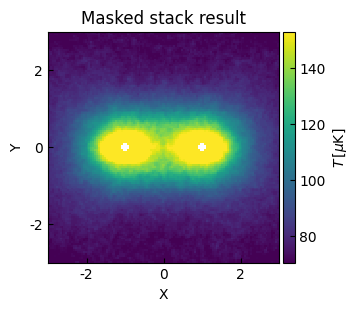

In [ ]:
# data = np.load('../data/tng_pairstack_result_cube.npz', 'r')['data']
stack_result = np.load("../data/tng_pairstack_result_hpmap.npz", "r")["data"]
# data = np.load('../data/crafts_pairstack_result_airpls.npz', 'r')['data']

halo_peak_mask = get_mask_sector(rlim=[0.0, 0.1], thetalim=[-np.pi / 2, np.pi / 2])
stack_result_masked = np.ma.array(stack_result, mask=halo_peak_mask, fill_value=0)

plot_heatmap(stack_result_masked, title="Masked stack result", cmap="viridis")

## sector mask

<Axes: title={'center': 'Fitting mask'}, xlabel='X', ylabel='Y'>

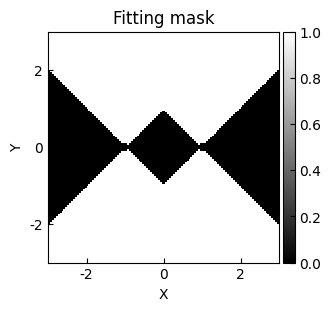

In [ ]:
fit_mask = get_mask_sector(rlim=[0.1, 5])
# fit_mask = ~get_mask_square()
plot_heatmap(fit_mask, title="Fitting mask", cmap="gray", cbar_label="")

## analytical model

In [217]:
coord = get_coord()
model = get_default_model()

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=50., x_mean=-1., y_mean=0., r_s=0.5)>

    [1]: <NFW2D(amplitude=50., x_mean=1., y_mean=0., r_s=0.5)>

    [2]: <Gaussian2D(amplitude=50., x_mean=-1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [3]: <Gaussian2D(amplitude=50., x_mean=1., y_mean=0., x_stddev=0.5, y_stddev=0.5, theta=0.)>

    [4]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 r_s_0 ... y_stddev_3 theta_3 amplitude_4
    ----------- -------- -------- ----- ... ---------- ------- -----------
           50.0     -1.0      0.0   0.5 ...        0.5     0.0         0.0
Fixed parameters are: ['x_mean_0', 'y_mean_0', 'x_mean_1', 'y_mean_1', 'x_mean_2', 'y_mean_2', 'x_mean_3', 'y_mean_3']
Tied parameters are: []
Paramters bounds are: [['amplitude_0', (0.0, 100.0)], ['r_s_0', (0.1, None)], ['amplitude_1', (0.0, 100.0)], ['r_s_1', (0.1, None)], [

In [ ]:
bounds = {
    "ellipticity_0": (0, 0.4),
    "ellipticity_1": (0, 0.4),
    "x_stddev_2": (0.1, None),
    "x_stddev_3": (0.1, None),
    "y_stddev_2": (0.1, None),
    "y_stddev_3": (0.1, None),
}
constraints = {
    "fixed": ["ellipticity_0", "ellipticity_1", "theta_0", "theta_1"],
    "tied": [("x_stddev_2", "x_stddev_3"), ("y_stddev_2", "y_stddev_3")],
    # "tied": [("x_stddev_2", "y_stddev_2"), ("y_stddev_3", "y_stddev_3")],
    # "tied": [("ellipticity_2", "ellipticity_3"),]
}
# model = apply_prior(model, bounds=bounds, constraints=constraints)
model.fixed

{'amplitude_0': False, 'x_mean_0': True, 'y_mean_0': True, 'r_s_0': False, 'ellipticity_0': True, 'theta_0': True, 'amplitude_1': False, 'x_mean_1': True, 'y_mean_1': True, 'r_s_1': False, 'ellipticity_1': True, 'theta_1': True, 'amplitude_2': False, 'x_mean_2': True, 'y_mean_2': True, 'x_stddev_2': False, 'y_stddev_2': False, 'theta_2': False, 'amplitude_3': False, 'x_mean_3': True, 'y_mean_3': True, 'x_stddev_3': False, 'y_stddev_3': False, 'theta_3': False, 'amplitude_4': False}

## analytical fitting

In [218]:
result_list, fitted_model, fit_info = halofit(
    coord, stack_result_masked, model=model, print_model=True, mask=fit_mask
)


Fitted model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2] + [3] + [4]
Components: 
    [0]: <NFW2D(amplitude=8.33820226, x_mean=-1., y_mean=0., r_s=2.17176922)>

    [1]: <NFW2D(amplitude=7.69066112, x_mean=1., y_mean=0., r_s=2.13419156)>

    [2]: <Gaussian2D(amplitude=29.59033904, x_mean=-1., y_mean=0., x_stddev=3.95669817, y_stddev=0.95109604, theta=-0.0042488)>

    [3]: <Gaussian2D(amplitude=47.09198574, x_mean=1., y_mean=0., x_stddev=3.04705311, y_stddev=0.5507532, theta=0.00171001)>

    [4]: <Const2D(amplitude=69.6195406)>
Parameters:
       amplitude_0    x_mean_0 y_mean_0 ...        theta_3           amplitude_4   
    ----------------- -------- -------- ... --------------------- -----------------
    8.338202260570206     -1.0      0.0 ... 0.0017100062739792085 69.61954060075873

Goodness of fit:
Chi-squared: 46463.822
Reduced chi-squared: 4.499
RMS residual: 2.119



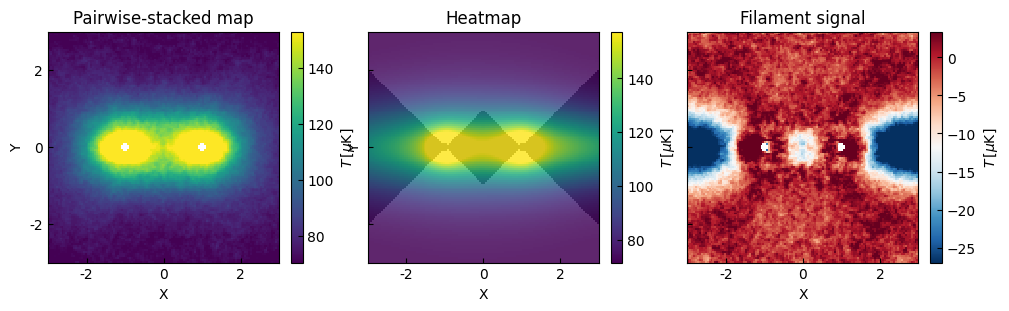

In [ ]:
axes = plot_stack_fit_res(
    result_list,  # pyright: ignore[reportArgumentType]
    norm="linear",
    cmap=["viridis", "viridis", "RdBu_r"],
    # vmax=[140,140,10],
    # vmin=[60, 60, -10],
    fit_mask=fit_mask,
)
fname = "img_tngcube_stack_fit_res_analytical.png"
# save_plot(axes, fname)

array([[<Axes: title={'center': 'Y=0'}, ylabel='$T\\,[\\mu$K]'>,
        <Axes: title={'center': 'X=-1'}>,
        <Axes: title={'center': 'X=1'}>],
       [<Axes: ylabel='$\\Delta$$T\\,[\\mu$K]'>, <Axes: >, <Axes: >]],
      dtype=object)

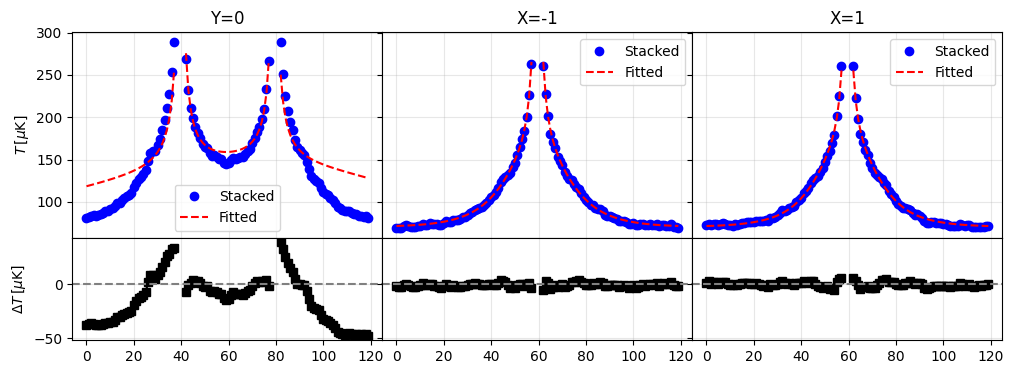

In [220]:
_, fitted, residual = result_list
fitted = np.ma.array(fitted, mask=halo_peak_mask)

compare_profiles([stack_result_masked, fitted])

<Axes: title={'center': 'Normalized Residual'}, xlabel='X', ylabel='Y'>

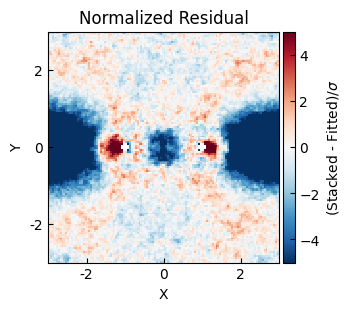

In [221]:
plot_heatmap(
    residual / 2.5,
    title="Normalized Residual",
    cmap="RdBu_r",
    cbar_label=r"(Stacked - Fitted)/$\sigma$",
    vmax=5,
    vmin=-5,
)

In [222]:
bg_mean, bg_std = residual[fit_mask].mean(), residual[fit_mask].std()
bg_mean, bg_std

(np.float64(3.942659577081398e-06), np.float64(2.1189916926066683))

## fitting error

Fitting model to original data...
Running 10 bootstrap iterations...
  Completed 1/10 iterations (1 successful)
  Completed 2/10 iterations (2 successful)
  Completed 3/10 iterations (3 successful)
  Completed 4/10 iterations (4 successful)
  Completed 5/10 iterations (5 successful)
  Completed 6/10 iterations (6 successful)
  Completed 7/10 iterations (7 successful)
  Completed 8/10 iterations (8 successful)
  Completed 9/10 iterations (9 successful)
  Completed 10/10 iterations (10 successful)

Bootstrap error map statistics:
  Min: 0.188808
  Max: 7.714587
  Median: 0.384691
  Mean: 0.465478

Parameter uncertainties from bootstrap:
  amplitude_0: 2.639884 (relative: 35.768%)
  x_mean_0: 0.000000 (relative: 0.000%)
  y_mean_0: 0.000000 (relative: nan%)
  r_s_0: 1.109711 (relative: 39.921%)
  amplitude_1: 1.491241 (relative: 21.238%)
  x_mean_1: 0.000000 (relative: 0.000%)
  y_mean_1: 0.000000 (relative: nan%)
  r_s_1: 0.532336 (relative: 21.935%)
  amplitude_2: 7.092839 (relative: 22

<string>:80: RuntimeWarning: invalid value encountered in scalar divide


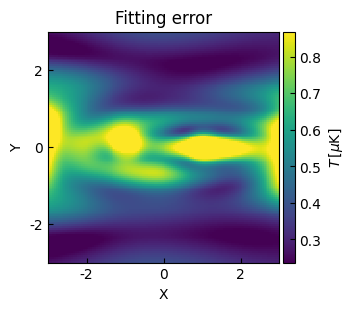

In [223]:
from crafts_stack.halo_fitting import get_fitting_error_bootstrap

error_map = get_fitting_error_bootstrap(fitted_model, *coord, stack_result_masked, n_bootstrap=10)
plot_heatmap(error_map, title="Fitting error");

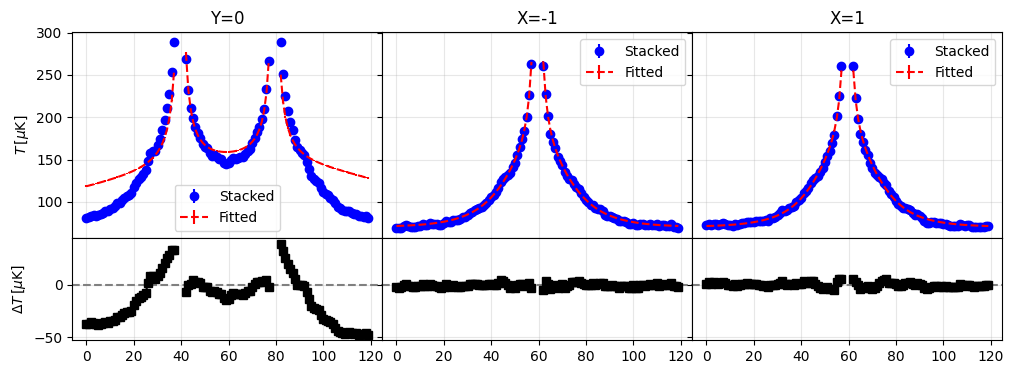

In [224]:
compare_profiles([stack_result_masked, fitted], [np.zeros_like(fitted), error_map]);

# Estimate filament signal level

In [225]:
from mytools.estimate_with_error import get_signal_level
from mytools.plot import plot_profile_2c

Parameter names:
('amplitude_0', 'mean_0', 'stddev_0', 'amplitude_1')
Gauss fit parameters: [np.float64(-9.890104620823651), np.float64(0.0), np.float64(0.28246103850057025), np.float64(-1.0025000681225746)]
Gauss fit covariance (without fix mean): 
[[ 4.24017469e-03  7.41468448e-05 -3.61287613e-05]
 [ 7.41468448e-05  3.41913170e-06  2.42582495e-06]
 [-3.61287613e-05  2.42582495e-06  5.90114483e-05]]
0 points clipped during sigma clipping.

Goodness of fit:
Chi-squared: 175.340
Reduced chi-squared: 1.499
RMS residual: 1.209

width: 0.28246103850057025
width_pix: 6


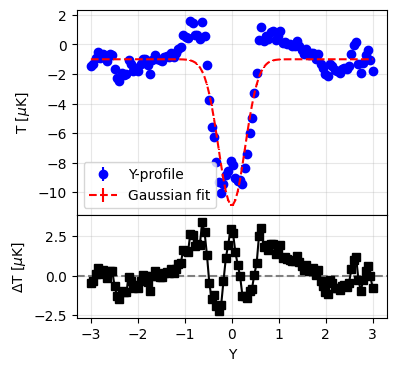

In [226]:
bounds = {
    "amplitude_0": (-np.inf, np.inf),
    "stddev_0": (0, 0.6),
}

lx, ly, ly_error, clrb, clrb_err, params, cov = get_signal_level(
    residual, error_map, bounds=bounds
)

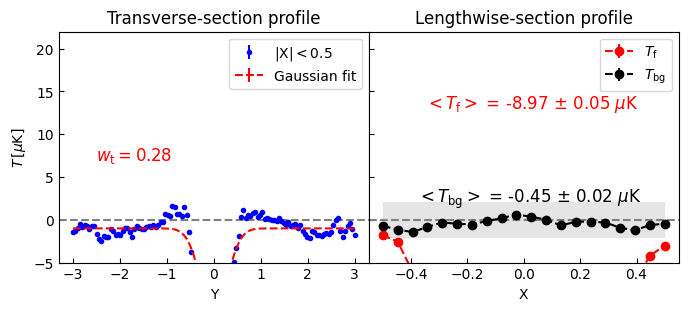

In [227]:
text_pos = [[-0.35, 13], [-0.38, 2], [-2.5, 7]]
axes = plot_profile_2c(lx, ly, width=params[2], y_err=ly_error, text_pos=text_pos)
axes[0].set_ylim(-5, 22)
axes[1].fill_between(
    lx[-1], bg_mean + bg_std, bg_mean - bg_std, facecolor="gray", alpha=0.2
)

# Check submodel contributions

<Axes: title={'center': 'Lorentz contribution'}, xlabel='X', ylabel='Y'>

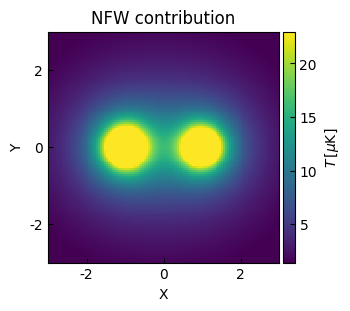

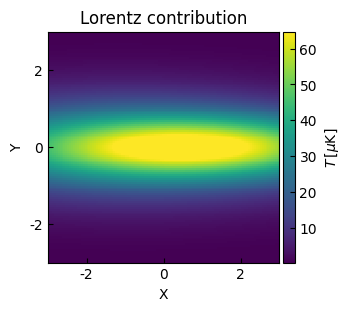

In [228]:
submodel_contris = get_submodel_contributions(fitted_model, *coord)
contris_nfw = submodel_contris[0] + submodel_contris[1]
contris_lorentz = submodel_contris[2] + submodel_contris[3]
contris_bg = submodel_contris[4]
plot_heatmap(contris_nfw, title="NFW contribution", cmap="viridis")
plot_heatmap(contris_lorentz, title="Lorentz contribution", cmap="viridis")